# CUGDL — Análisis de admisiones
**Centro Universitario de Guadalajara · Red UdeG**

Análisis de admitidos, puntajes mínimos, cupos y tasas de admisión por carrera y ciclo escolar del CUGDL, el centro donde estudia el autor.

**Alcance:** solo programas **presenciales** (`es_virtual = 0`). El CUGDL ofrece además programas virtuales con puntaje mínimo fijo, que se excluyen para no distorsionar la comparación de selectividad. Los programas presenciales son de reciente creación: solo hay **3 ciclos disponibles (2024B, 2025A y 2025B)**, y el año 2024 incluye únicamente el periodo B, por lo que las comparaciones anuales deben leerse con cautela y la lectura de tendencias es **exploratoria**.

> Requiere la base `udg_analisis` cargada (`sql/01_schema.sql` y `sql/02_datos.sql`) y un archivo `.env` (ver `.env.example`).

## 0 · Configuración e Imports

In [1]:
import os
from pathlib import Path
from urllib.parse import quote_plus

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
from matplotlib.gridspec import GridSpec
import warnings
from dotenv import load_dotenv, find_dotenv
from sqlalchemy import create_engine
warnings.filterwarnings('ignore')

FIG_DIR = Path("../reports/figures/cugdl")     # gráficas exportadas
OUT_DIR = Path("../data/processed")            # tablas exportadas
FIG_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

# ── Paleta CUGDL ──────────────────────────────────────────────────────────────
AZUL        = '#003087'   # azul institucional UdeG
DORADO      = '#C8A84B'   # dorado UdeG
AZUL_CLARO  = '#2563A8'   # azul medio (barras secundarias)
ROJO        = '#C0392B'   # acento para valores bajos / alertas
GRIS_FONDO  = '#F5F6FA'   # fondo de figuras
GRIS_BORDE  = '#DDE1EC'   # bordes y líneas de grid
BLANCO      = '#FFFFFF'

PALETA_CARRERAS = [
    '#003087', '#2563A8', '#C8A84B', '#4A90D9',
    '#1A5276', '#D4AC0D', '#85929E', '#2ECC71'
]

# ── Estilo global ─────────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.facecolor'   : GRIS_FONDO,
    'axes.facecolor'     : BLANCO,
    'axes.edgecolor'     : GRIS_BORDE,
    'axes.grid'          : True,
    'grid.color'         : GRIS_BORDE,
    'grid.linestyle'     : '--',
    'grid.alpha'         : 0.7,
    'font.family'        : 'DejaVu Sans',
    'axes.titlesize'     : 13,
    'axes.titleweight'   : 'bold',
    'axes.titlecolor'    : AZUL,
    'axes.labelsize'     : 10,
    'axes.labelcolor'    : '#333333',
    'xtick.labelsize'    : 9,
    'ytick.labelsize'    : 9,
    'legend.fontsize'    : 9,
    'legend.framealpha'  : 0.9,
})

def header_fig(fig, titulo, subtitulo=''):
    """Agrega encabezado institucional CUGDL a una figura."""
    fig.text(0.01, 0.98, 'CUGDL · Centro Universitario de Guadalajara',
             fontsize=9, color=DORADO, va='top', style='italic')
    fig.text(0.5, 0.98, titulo,
             fontsize=15, fontweight='bold', color=AZUL, va='top', ha='center')
    if subtitulo:
        fig.text(0.5, 0.945, subtitulo,
                 fontsize=9, color='#555555', va='top', ha='center')

print('✅ Librerías y estilos listos.')

✅ Librerías y estilos listos.


## 1 · Conexión y Extracción de Datos

In [2]:
# ── Conexión a MySQL (credenciales en .env, nunca en el código) ─────────────────
load_dotenv(find_dotenv(usecwd=True))

DB_USER     = os.getenv("DB_USER", "root")
DB_PASSWORD = os.getenv("DB_PASSWORD", "")
DB_HOST     = os.getenv("DB_HOST", "localhost")
DB_NAME     = os.getenv("DB_NAME", "udg_analisis")

engine = create_engine(
    f"mysql+mysqlconnector://{DB_USER}:{quote_plus(DB_PASSWORD)}@{DB_HOST}/{DB_NAME}"
)

def query(sql):
    return pd.read_sql(sql, engine)

# ── Query principal: admisión de los programas presenciales del CUGDL ───────────
SQL_CUGDL = """
SELECT
    CONCAT(ce.año, ce.periodo)                      AS ciclo,
    ce.año                                          AS anio,
    ce.periodo,
    ca.nombre                                       AS carrera,
    a.aspirantes,
    a.cupo,
    a.admitidos,
    (a.aspirantes - a.admitidos)                    AS no_admitidos,
    a.puntaje_minimo,
    ROUND(a.admitidos / a.aspirantes * 100, 2)      AS tasa_admision,
    ROUND(a.admitidos / NULLIF(a.cupo,0) * 100, 2)  AS ocupacion_cupo
FROM admision a
JOIN ciclo_escolar        ce ON a.id_ciclo   = ce.id_ciclo
JOIN carrera              ca ON a.id_carrera = ca.id_carrera
JOIN centro_universitario cu ON ca.id_centro = cu.id_centro
WHERE cu.nombre = 'CUGDL'
  AND ca.es_virtual = 0
ORDER BY ce.año, ce.periodo, ca.nombre;
"""

df = query(SQL_CUGDL)
df['no_admitidos'] = df['no_admitidos'].clip(lower=0)   # evita negativos por cupos ampliados
print(f'✅ {len(df)} registros cargados.')
df.head(10)

✅ 15 registros cargados.


,ciclo,anio,periodo,carrera,aspirantes,cupo,admitidos,no_admitidos,puntaje_minimo,tasa_admision,ocupacion_cupo
0,2024B,2024,B,LICENCIATURA EN CIBERSEGURIDAD,244,90,90,154,129.0000,36.89,100.0
1,2024B,2024,B,LICENCIATURA EN CREATIVIDAD DIGITAL,324,150,150,174,139.2233,46.30,100.0
2,2024B,2024,B,LICENCIATURA EN INTELIGENCIA ARTIFICIAL Y CIEN...,368,120,120,248,143.6667,32.61,100.0
3,2024B,2024,B,LICENCIATURA EN INTELIGENCIA FINANCIERA Y DE N...,352,150,150,202,134.0033,42.61,100.0
4,2024B,2024,B,LICENCIATURA EN TECNOLOGIAS BIOMEDICAS,246,90,90,156,138.5833,36.59,100.0
5,2025A,2025,A,LICENCIATURA EN CIBERSEGURIDAD,131,90,90,41,122.9400,68.70,100.0
6,2025A,2025,A,LICENCIATURA EN CREATIVIDAD DIGITAL,246,150,150,96,135.6000,60.98,100.0
7,2025A,2025,A,LICENCIATURA EN INTELIGENCIA ARTIFICIAL Y CIEN...,184,120,120,64,136.4633,65.22,100.0
8,2025A,2025,A,LICENCIATURA EN INTELIGENCIA FINANCIERA Y DE N...,169,120,120,49,124.5000,71.01,100.0
9,2025A,2025,A,LICENCIATURA EN TECNOLOGIAS BIOMEDICAS,79,60,60,19,125.0633,75.95,100.0


## 2 · Exploración Rápida

In [3]:
print('── Ciclos disponibles ──────────────────────────────')
print(sorted(df['ciclo'].unique()))

print('\n── Carreras ────────────────────────────────────────')
for c in sorted(df['carrera'].unique()):
    print(' ·', c)

print('\n── Resumen estadístico ─────────────────────────────')
df[['aspirantes','cupo','admitidos','puntaje_minimo','tasa_admision']].describe().round(2)

── Ciclos disponibles ──────────────────────────────
['2024B', '2025A', '2025B']

── Carreras ────────────────────────────────────────
 · LICENCIATURA EN CIBERSEGURIDAD
 · LICENCIATURA EN CREATIVIDAD DIGITAL
 · LICENCIATURA EN INTELIGENCIA ARTIFICIAL Y CIENCIA DE LOS DATOS
 · LICENCIATURA EN INTELIGENCIA FINANCIERA Y DE NEGOCIOS
 · LICENCIATURA EN TECNOLOGIAS BIOMEDICAS

── Resumen estadístico ─────────────────────────────


,aspirantes,cupo,admitidos,puntaje_minimo,tasa_admision
count,15.00,15.00,15.00,15.00,15.00
mean,227.33,116.00,116.00,132.90,55.63
std,90.45,33.76,33.76,7.56,15.17
min,76.00,60.00,60.00,117.17,32.61
25%,176.50,90.00,90.00,127.03,44.46
50%,242.00,120.00,120.00,135.60,60.98
75%,281.00,150.00,150.00,138.21,66.96
max,368.00,150.00,150.00,143.67,78.95


In [4]:
# ── Agrupado por año (suma ambos periodos A+B) ────────────────────────────────
df_anio = (
    df.groupby(['anio', 'carrera'])
      .agg(
          aspirantes    = ('aspirantes',     'sum'),
          cupo          = ('cupo',           'sum'),
          admitidos     = ('admitidos',      'sum'),
          no_admitidos  = ('no_admitidos',   'sum'),
          puntaje_min   = ('puntaje_minimo', 'min'),   # puntaje mínimo del año
          puntaje_max   = ('puntaje_minimo', 'max'),   # puntaje mínimo máximo del año
      )
      .reset_index()
)
df_anio['tasa_admision'] = (df_anio['admitidos'] / df_anio['aspirantes'] * 100).round(2)

# Totales por año (todas las carreras)
df_total_anio = (
    df.groupby('anio')
      .agg(
          aspirantes   = ('aspirantes',   'sum'),
          cupo         = ('cupo',         'sum'),
          admitidos    = ('admitidos',    'sum'),
          no_admitidos = ('no_admitidos', 'sum'),
      )
      .reset_index()
)
df_total_anio['tasa_admision'] = (df_total_anio['admitidos'] / df_total_anio['aspirantes'] * 100).round(2)

print('✅ DataFrames auxiliares listos.')
df_total_anio

✅ DataFrames auxiliares listos.


,anio,aspirantes,cupo,admitidos,no_admitidos,tasa_admision
0,2024,1534,600,600,934,39.11
1,2025,1876,1140,1140,736,60.77


---
## 3 · Visualización 1 — Ranking de Carreras por Tasa de Admisión
*¿Cuáles son las carreras más y menos competidas del CUGDL?*

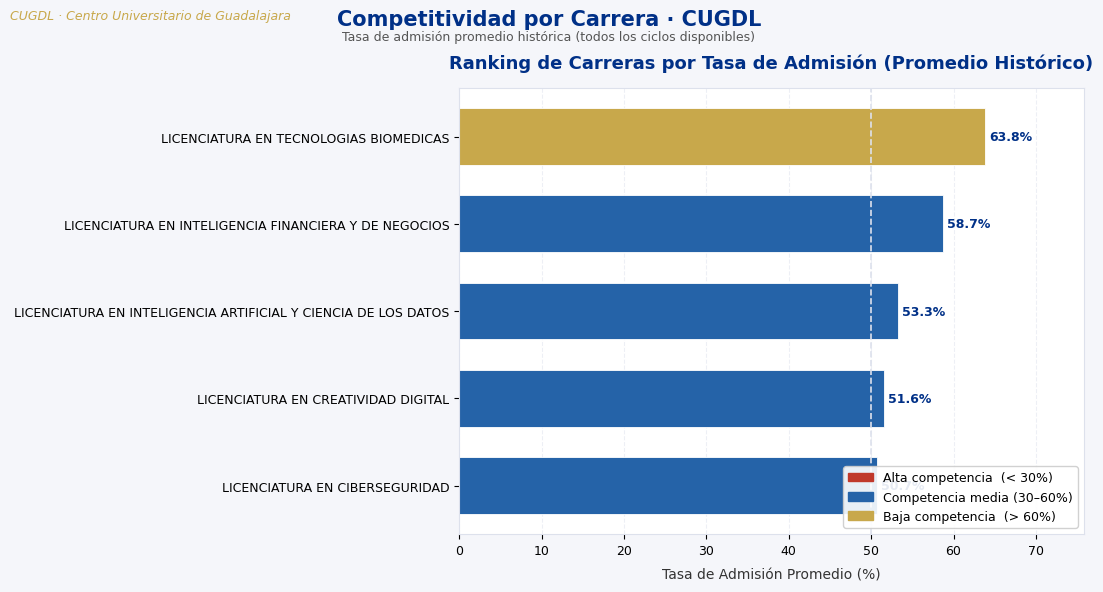

In [5]:
# Promedio histórico de tasa de admisión por carrera
ranking = (
    df.groupby('carrera')
      .agg(tasa_admision=('tasa_admision', 'mean'),
           aspirantes_total=('aspirantes', 'sum'))
      .reset_index()
      .sort_values('tasa_admision')
)

fig, ax = plt.subplots(figsize=(11, 6))
fig.patch.set_facecolor(GRIS_FONDO)

colores = [ROJO if t < 30 else AZUL_CLARO if t < 60 else DORADO
           for t in ranking['tasa_admision']]

bars = ax.barh(ranking['carrera'], ranking['tasa_admision'],
               color=colores, edgecolor='white', linewidth=0.6, height=0.65)

# Etiquetas de valor
for bar, val in zip(bars, ranking['tasa_admision']):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
            f'{val:.1f}%', va='center', fontsize=9, color=AZUL, fontweight='bold')

# Línea de referencia 50%
ax.axvline(50, color=GRIS_BORDE, linewidth=1.2, linestyle='--', label='Ref. 50%')

ax.set_xlabel('Tasa de Admisión Promedio (%)', labelpad=8)
ax.set_xlim(0, ranking['tasa_admision'].max() + 12)
ax.set_title('Ranking de Carreras por Tasa de Admisión (Promedio Histórico)', pad=14)
ax.grid(axis='x', linestyle='--', alpha=0.5)
ax.grid(axis='y', visible=False)
ax.set_axisbelow(True)

leyenda = [
    mpatches.Patch(color=ROJO,      label='Alta competencia  (< 30%)'),
    mpatches.Patch(color=AZUL_CLARO,label='Competencia media (30–60%)'),
    mpatches.Patch(color=DORADO,    label='Baja competencia  (> 60%)'),
]
ax.legend(handles=leyenda, loc='lower right', framealpha=0.9)

header_fig(fig, 'Competitividad por Carrera · CUGDL',
           'Tasa de admisión promedio histórica (todos los ciclos disponibles)')

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.savefig(FIG_DIR / '01_ranking_tasa_admision.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 4 · Visualización 2 — Aspirantes vs Cupo vs Admitidos por Año
*Visión global de la demanda y la oferta del CUGDL a lo largo del tiempo.*

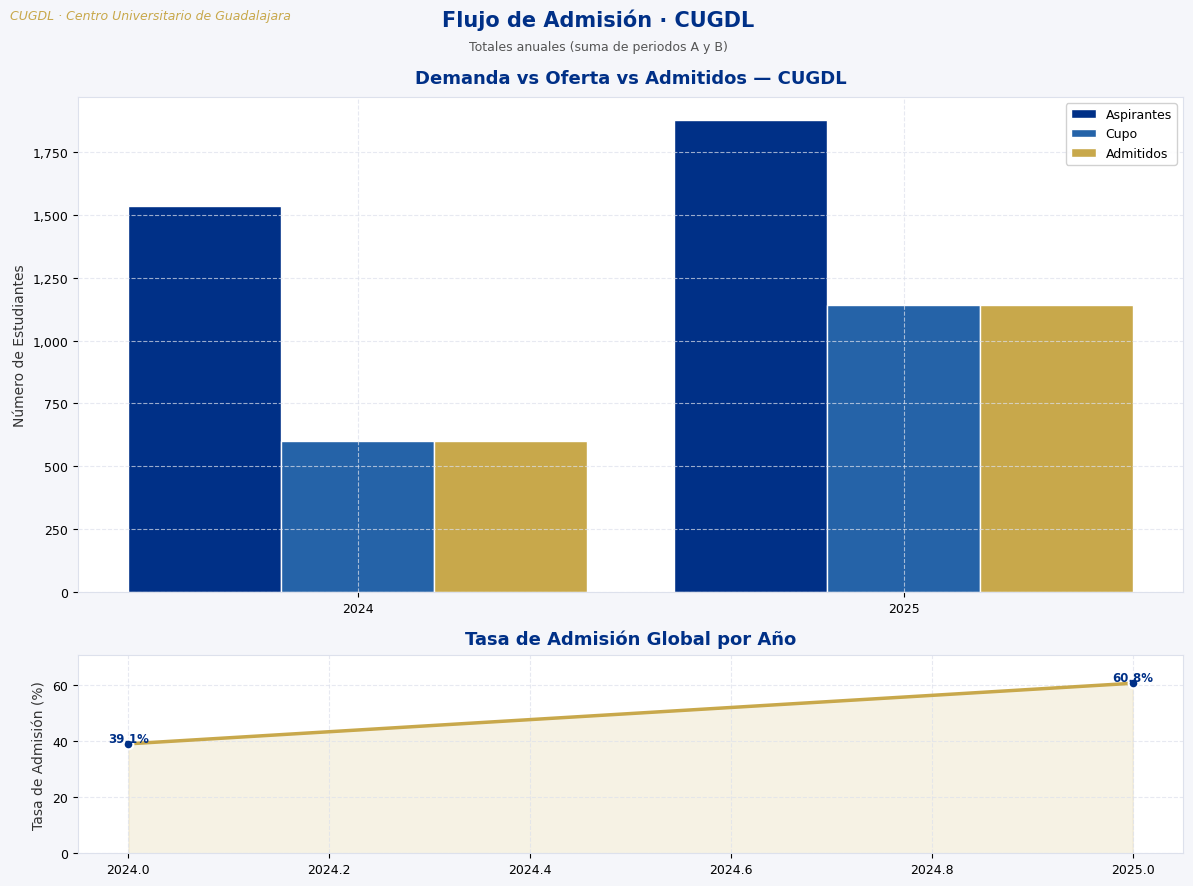

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(12, 9), gridspec_kw={'height_ratios': [3, 1.2]})
fig.patch.set_facecolor(GRIS_FONDO)

# ── Panel superior: barras agrupadas ─────────────────────────────────────────
ax1 = axes[0]
x   = np.arange(len(df_total_anio))
w   = 0.28

ax1.bar(x - w, df_total_anio['aspirantes'],  w, label='Aspirantes', color=AZUL,       edgecolor='white')
ax1.bar(x,     df_total_anio['cupo'],         w, label='Cupo',       color=AZUL_CLARO, edgecolor='white')
ax1.bar(x + w, df_total_anio['admitidos'],    w, label='Admitidos',  color=DORADO,     edgecolor='white')

ax1.set_xticks(x)
ax1.set_xticklabels(df_total_anio['anio'], rotation=0)
ax1.set_ylabel('Número de Estudiantes')
ax1.set_title('Demanda vs Oferta vs Admitidos — CUGDL', pad=10)
ax1.legend(loc='upper right')
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))

# ── Panel inferior: tasa de admisión total ────────────────────────────────────
ax2 = axes[1]
ax2.plot(df_total_anio['anio'], df_total_anio['tasa_admision'],
         color=DORADO, linewidth=2.5, marker='o', markersize=7,
         markerfacecolor=AZUL, markeredgecolor='white', markeredgewidth=1.5)

ax2.fill_between(df_total_anio['anio'], df_total_anio['tasa_admision'],
                 alpha=0.15, color=DORADO)

# Etiquetas en puntos
for _, row in df_total_anio.iterrows():
    ax2.text(row['anio'], row['tasa_admision'] + 0.8,
             f"{row['tasa_admision']:.1f}%",
             ha='center', fontsize=8.5, color=AZUL, fontweight='bold')

ax2.set_ylabel('Tasa de Admisión (%)')
ax2.set_title('Tasa de Admisión Global por Año', pad=8)
ax2.set_ylim(0, df_total_anio['tasa_admision'].max() + 10)

header_fig(fig, 'Flujo de Admisión · CUGDL',
           'Totales anuales (suma de periodos A y B)')

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.savefig(FIG_DIR / '02_aspirantes_cupo_admitidos.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 5 · Visualización 3 — Evolución del Puntaje Mínimo por Carrera
*¿Qué tan exigente ha sido cada carrera a lo largo del tiempo?*

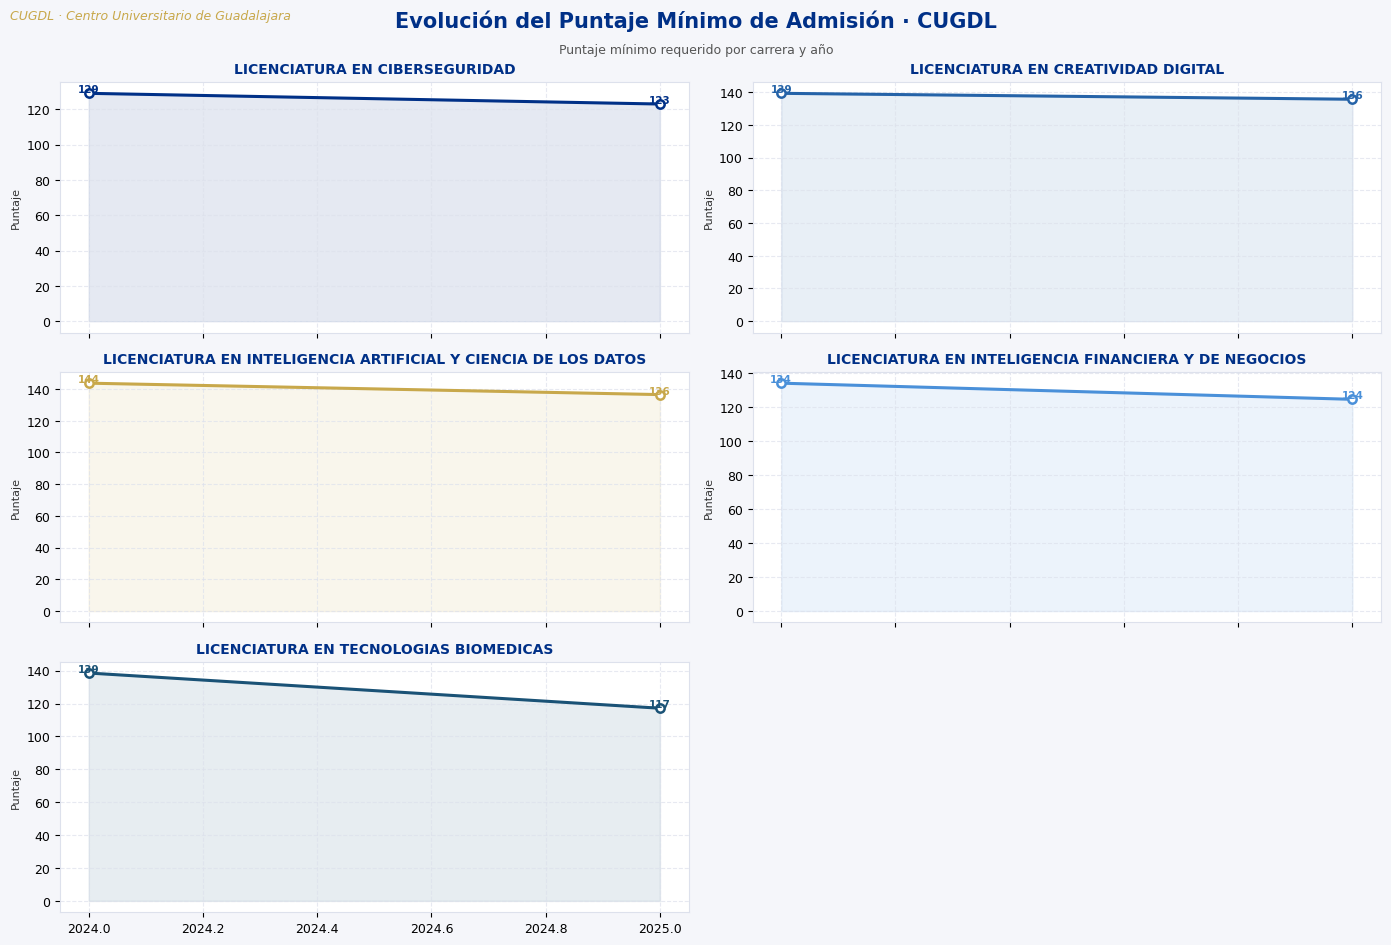

In [7]:
carreras = sorted(df['carrera'].unique())
n = len(carreras)
cols = 2
rows = (n + 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(14, rows * 3.2), sharex=True)
fig.patch.set_facecolor(GRIS_FONDO)
axes_flat = axes.flatten()

for i, carrera in enumerate(carreras):
    ax = axes_flat[i]
    d  = df_anio[df_anio['carrera'] == carrera].sort_values('anio')

    color = PALETA_CARRERAS[i % len(PALETA_CARRERAS)]

    ax.plot(d['anio'], d['puntaje_min'],
            color=color, linewidth=2.2, marker='o', markersize=6,
            markerfacecolor='white', markeredgewidth=1.8, label='Puntaje mín.')

    ax.fill_between(d['anio'], d['puntaje_min'],
                    alpha=0.10, color=color)

    ax.set_title(carrera, fontsize=10)
    ax.set_ylabel('Puntaje', fontsize=8)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x)}'))

    # Etiqueta del valor en cada punto
    for _, row in d.iterrows():
        ax.text(row['anio'], row['puntaje_min'] + 0.5,
                f"{row['puntaje_min']:.0f}",
                ha='center', fontsize=7.5, color=color, fontweight='bold')

# Ocultar subplots vacíos si n es impar
for j in range(n, len(axes_flat)):
    axes_flat[j].set_visible(False)

header_fig(fig, 'Evolución del Puntaje Mínimo de Admisión · CUGDL',
           'Puntaje mínimo requerido por carrera y año')

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig(FIG_DIR / '03_puntaje_minimo.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 6 · Visualización 4 — Tasa de Admisión por Carrera y Año (Heatmap)
*Mapa de calor para identificar de un vistazo los años y carreras más competidos.*

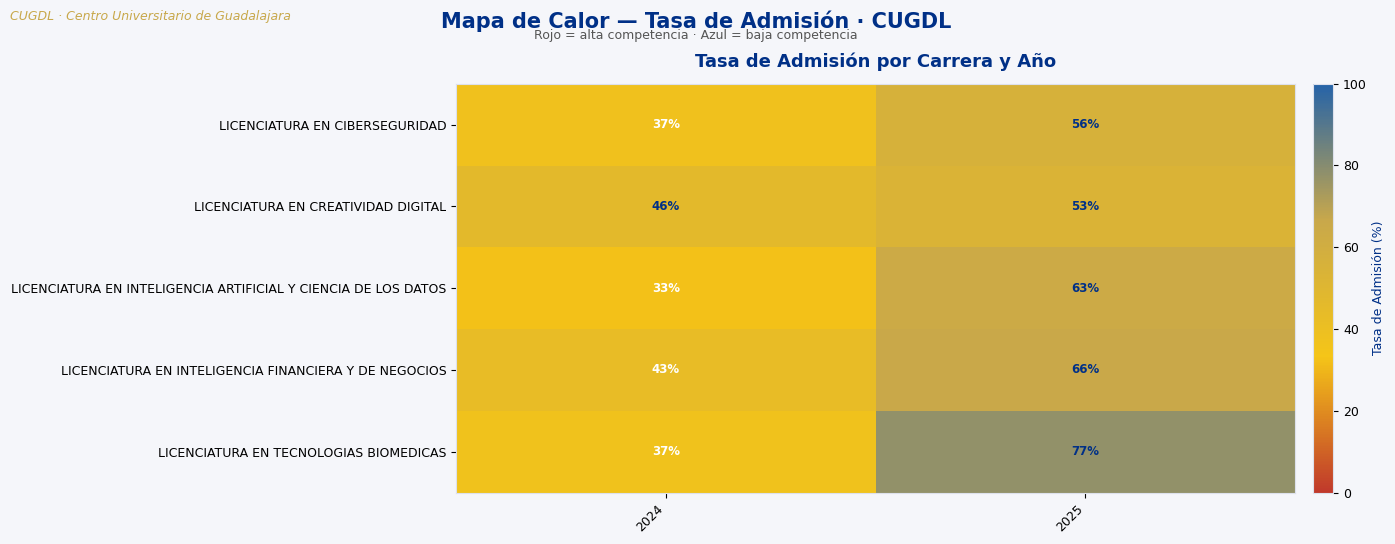

In [8]:
import matplotlib.colors as mcolors

pivot = df_anio.pivot(index='carrera', columns='anio', values='tasa_admision')

# Colormap: rojo (alta competencia) → dorado → azul (baja competencia)
cmap = mcolors.LinearSegmentedColormap.from_list(
    'cugdl', [ROJO, '#F5C518', DORADO, AZUL_CLARO]
)

fig, ax = plt.subplots(figsize=(14, max(5, len(carreras) * 0.7 + 2)))
fig.patch.set_facecolor(GRIS_FONDO)

im = ax.imshow(pivot.values, aspect='auto', cmap=cmap, vmin=0, vmax=100)

ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels(pivot.columns, rotation=45, ha='right')
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(pivot.index, fontsize=9)

# Valores dentro de cada celda
for r in range(pivot.shape[0]):
    for c in range(pivot.shape[1]):
        val = pivot.values[r, c]
        if not np.isnan(val):
            color_txt = 'white' if val < 45 or val > 80 else AZUL
            ax.text(c, r, f'{val:.0f}%',
                    ha='center', va='center',
                    fontsize=8.5, fontweight='bold', color=color_txt)

cbar = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
cbar.set_label('Tasa de Admisión (%)', color=AZUL, fontsize=9)

ax.set_title('Tasa de Admisión por Carrera y Año', pad=12)
ax.grid(visible=False)

header_fig(fig, 'Mapa de Calor — Tasa de Admisión · CUGDL',
           'Rojo = alta competencia · Azul = baja competencia')

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.savefig(FIG_DIR / '04_heatmap_tasa_admision.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 7 · Visualización 5 — Dashboard Resumen del Último Ciclo
*Snapshot del ciclo más reciente disponible en la base de datos.*

📅 Ciclo más reciente: 2025B  (5 carreras)


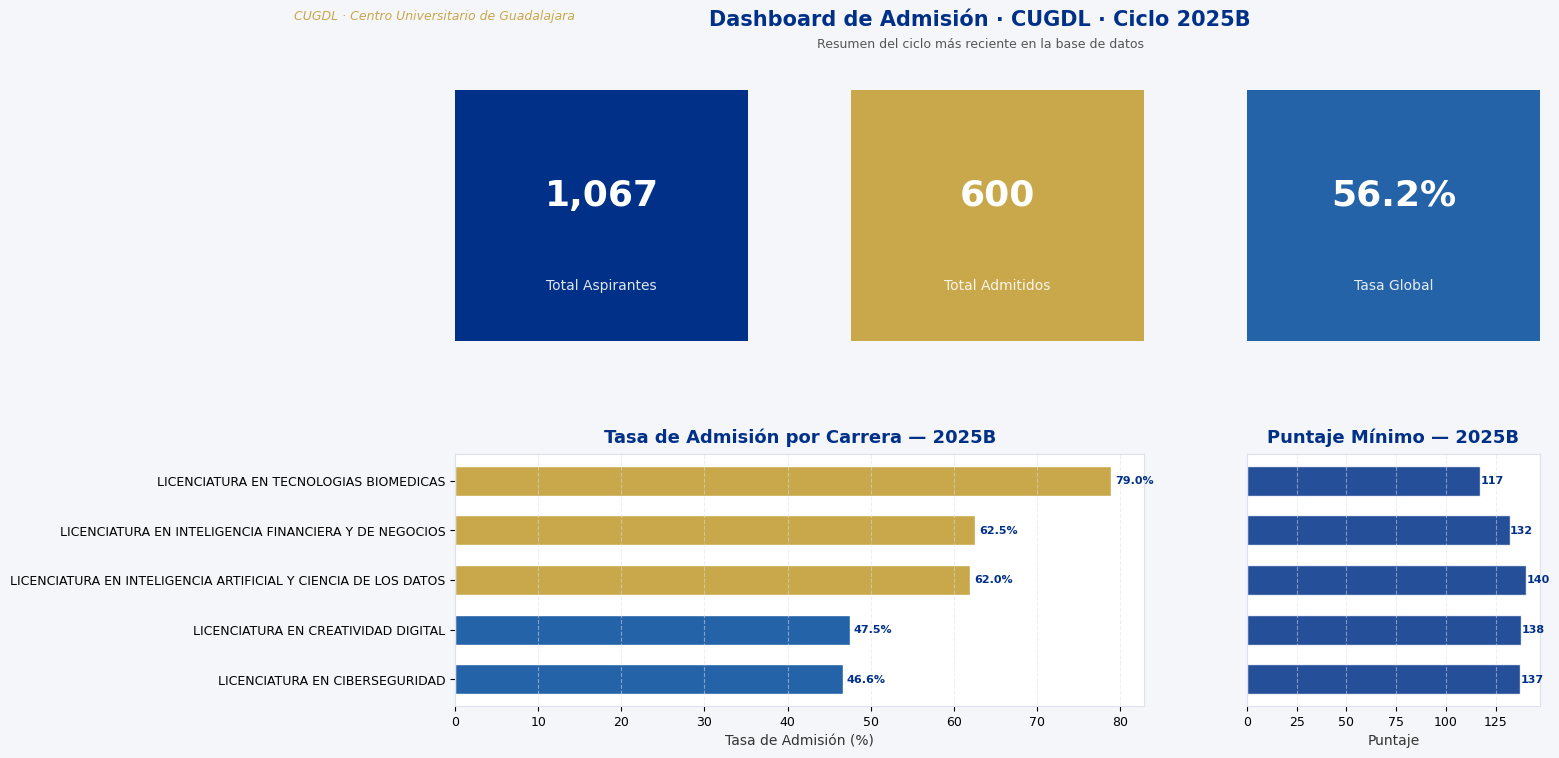

In [9]:
ultimo_ciclo = df['ciclo'].max()
df_ultimo    = df[df['ciclo'] == ultimo_ciclo].copy()

print(f'📅 Ciclo más reciente: {ultimo_ciclo}  ({len(df_ultimo)} carreras)')

fig = plt.figure(figsize=(14, 8))
fig.patch.set_facecolor(GRIS_FONDO)
gs  = GridSpec(2, 3, figure=fig, hspace=0.45, wspace=0.35)

# ── KPIs en fila superior ─────────────────────────────────────────────────────
kpis = [
    ('Total Aspirantes',   f"{df_ultimo['aspirantes'].sum():,}",  AZUL),
    ('Total Admitidos',    f"{df_ultimo['admitidos'].sum():,}",   DORADO),
    ('Tasa Global',        f"{(df_ultimo['admitidos'].sum()/df_ultimo['aspirantes'].sum()*100):.1f}%", AZUL_CLARO),
]
for idx, (label, valor, color) in enumerate(kpis):
    ax_kpi = fig.add_subplot(gs[0, idx])
    ax_kpi.set_facecolor(color)
    ax_kpi.text(0.5, 0.58, valor,  ha='center', va='center',
                fontsize=26, fontweight='bold', color='white',
                transform=ax_kpi.transAxes)
    ax_kpi.text(0.5, 0.22, label,  ha='center', va='center',
                fontsize=10, color='white', alpha=0.88,
                transform=ax_kpi.transAxes)
    ax_kpi.set_xticks([])
    ax_kpi.set_yticks([])
    for spine in ax_kpi.spines.values():
        spine.set_visible(False)

# ── Fila inferior izq+centro: Barras de admitidos por carrera ─────────────────
ax_bar = fig.add_subplot(gs[1, :2])
df_ult_sorted = df_ultimo.sort_values('tasa_admision')
colores_bar   = [ROJO if t < 30 else AZUL_CLARO if t < 60 else DORADO
                 for t in df_ult_sorted['tasa_admision']]

ax_bar.barh(df_ult_sorted['carrera'], df_ult_sorted['tasa_admision'],
            color=colores_bar, edgecolor='white', height=0.6)

for val, patch in zip(df_ult_sorted['tasa_admision'], ax_bar.patches):
    ax_bar.text(patch.get_width() + 0.5,
                patch.get_y() + patch.get_height()/2,
                f'{val:.1f}%', va='center', fontsize=8, color=AZUL, fontweight='bold')

ax_bar.set_title(f'Tasa de Admisión por Carrera — {ultimo_ciclo}', pad=8)
ax_bar.set_xlabel('Tasa de Admisión (%)')
ax_bar.grid(axis='x', linestyle='--', alpha=0.5)
ax_bar.grid(axis='y', visible=False)

# ── Fila inferior der: Puntaje mínimo ─────────────────────────────────────────
ax_pnt = fig.add_subplot(gs[1, 2])
df_ult_pnt = df_ult_sorted   # mismo orden que el panel izquierdo: se leen carrera por carrera

ax_pnt.barh(df_ult_pnt['carrera'], df_ult_pnt['puntaje_minimo'],
            color=AZUL, alpha=0.85, edgecolor='white', height=0.6)

for val, patch in zip(df_ult_pnt['puntaje_minimo'], ax_pnt.patches):
    ax_pnt.text(patch.get_width() + 0.2,
                patch.get_y() + patch.get_height()/2,
                f'{val:.0f}', va='center', fontsize=8, color=AZUL, fontweight='bold')

ax_pnt.set_title(f'Puntaje Mínimo — {ultimo_ciclo}', pad=8)
ax_pnt.set_xlabel('Puntaje')
ax_pnt.tick_params(axis='y', left=False, labelleft=False)   # las carreras ya se leen en el panel izquierdo
ax_pnt.grid(axis='x', linestyle='--', alpha=0.5)
ax_pnt.grid(axis='y', visible=False)

header_fig(fig, f'Dashboard de Admisión · CUGDL · Ciclo {ultimo_ciclo}',
           'Resumen del ciclo más reciente en la base de datos')

plt.savefig(FIG_DIR / '05_dashboard_ultimo_ciclo.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 8 · Tabla Resumen Exportable

In [10]:
# Estadísticas históricas por carrera
resumen = (
    df.groupby('carrera')
      .agg(
          ciclos              = ('ciclo',         'count'),
          aspirantes_total    = ('aspirantes',     'sum'),
          admitidos_total     = ('admitidos',      'sum'),
          tasa_promedio       = ('tasa_admision',  'mean'),
          puntaje_min_hist    = ('puntaje_minimo', 'min'),
          puntaje_max_hist    = ('puntaje_minimo', 'max'),
          puntaje_promedio    = ('puntaje_minimo', 'mean'),
      )
      .reset_index()
      .sort_values('tasa_promedio')
)
resumen['tasa_promedio']    = resumen['tasa_promedio'].round(2)
resumen['puntaje_promedio'] = resumen['puntaje_promedio'].round(1)

resumen.to_csv(OUT_DIR / 'resumen_cugdl_admisiones.csv', index=False, encoding='utf-8-sig')
print('📄 Tabla exportada: data/processed/resumen_cugdl_admisiones.csv')
resumen

📄 Tabla exportada: data/processed/resumen_cugdl_admisiones.csv


,carrera,ciclos,aspirantes_total,admitidos_total,tasa_promedio,puntaje_min_hist,puntaje_max_hist,puntaje_promedio
0,LICENCIATURA EN CIBERSEGURIDAD,3,568,270,50.74,122.9400,137.1667,129.7
1,LICENCIATURA EN CREATIVIDAD DIGITAL,3,886,450,51.58,135.6000,139.2233,137.6
2,LICENCIATURA EN INTELIGENCIA ARTIFICIAL Y CIEN...,3,794,390,53.27,136.4633,143.6667,140.1
3,LICENCIATURA EN INTELIGENCIA FINANCIERA Y DE N...,3,761,420,58.71,124.5000,134.0033,130.2
4,LICENCIATURA EN TECNOLOGIAS BIOMEDICAS,3,401,210,63.83,117.1667,138.5833,126.9
